# Beams and HWP Mueller matrices

`sbm.systematics.beam` returns the whole signal of the sky seen through an
arbitrary beam, with or without a rotating HWP of real Mueller matrix (in the
narrow-beam approximation). `sbm.beam.convolve` gives the spin components alone.

In [1]:
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

import sbm
from sbm import systematics as sy

hmaps = sbm.HMaps.load_legacy("../tests/nside_32_boresight_hwp.h5")
nside = hmaps.nside
lmax = 2 * nside
cmb = sbm.generate_cmb(128, r=0.0, cmb_seed=33)
sky_alm = np.array(hp.map2alm(hp.ud_grade(cmb, nside), lmax=lmax))

## An elliptical beam

`elliptical_beam` gives the I, Q, U maps of an elliptical Gaussian beam at the
north pole; their harmonic coefficients are the `beam_alm`.

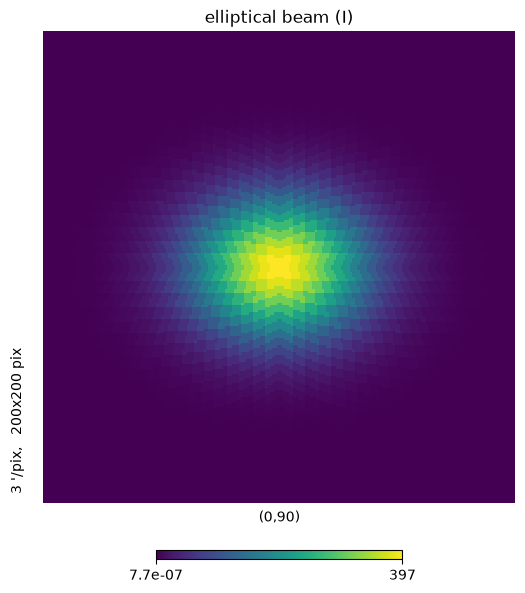

In [2]:
fwhm = np.deg2rad(3.0)
beam_maps = sbm.beam.elliptical_beam(256, fwhm, q=0.8)
beam_alm = np.array(hp.map2alm(beam_maps, lmax=lmax))
round_alm = np.array(hp.map2alm(sbm.beam.elliptical_beam(256, fwhm, q=1.0), lmax=lmax))
hp.gnomview(beam_maps[0], rot=(0, 90), reso=3, title="elliptical beam (I)")

## Without HWP

The ellipticity puts power at the crossing-angle moments $n = \pm 2$; with the
cross-linking of the scan it leaks temperature into polarization.

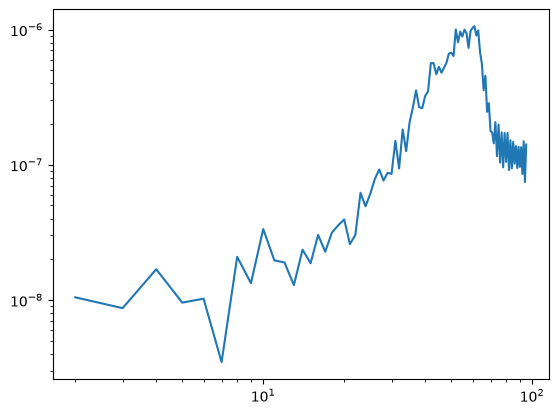

In [3]:
spins = range(5)
basis = sbm.Basis.iqu(hwp=False)
mask = hmaps.crosslink_mask(1.0)
ellip = sbm.map_make((hmaps, sy.beam(sky_alm, beam_alm, nside, spins)), basis, mask=mask).iqu
round_ = sbm.map_make((hmaps, sy.beam(sky_alm, round_alm, nside, spins)), basis, mask=mask).iqu
ell = np.arange(3 * nside)
bb = hp.anafast(np.nan_to_num(ellip - round_))[2]
plt.loglog(ell[2:], bb[2:], label="elliptical - round, no HWP")

## With a HWP

With an ideal HWP the polarization is modulated at spin $(2,-4)$ and the leakage
from the ellipticity is suppressed. A general Mueller matrix adds the 2f and
non-ideal 4f terms.

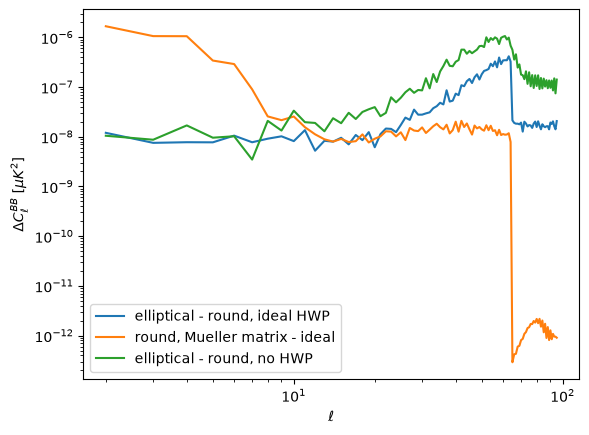

In [4]:
hwp_basis = sbm.Basis.iqu(hwp=True)
# 4f non-idealities only: the 2f terms (M_IQ, M_QI, ...) need HWP moments +/-2,
# which this scan does not have
general = np.array([[1.0, 0, 0, 0], [0, 0.98, 0.01, 0],
                    [0, 0.01, -0.97, 0], [0, 0, 0, -1.0]])
def hwp_map(beam_alm, mueller=None):
    model = sy.beam(sky_alm, beam_alm, nside, spins, hwp=True, mueller=mueller)
    return sbm.map_make((hmaps, model), hwp_basis).iqu
ref = hwp_map(round_alm)
for label, iqu in (("elliptical - round, ideal HWP", hwp_map(beam_alm)),
                   ("round, Mueller matrix - ideal", hwp_map(round_alm, general))):
    plt.loglog(ell[2:], hp.anafast(np.nan_to_num(iqu - ref))[2][2:], label=label)
plt.loglog(ell[2:], bb[2:], label="elliptical - round, no HWP")
plt.xlabel(r"$\ell$"); plt.ylabel(r"$\Delta C_\ell^{BB}$ [$\mu K^2$]"); plt.legend()